<a href="https://colab.research.google.com/github/roseTadiwa/AB-Testing-Analytics/blob/main/AB_Testing_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **A/B Testing Analytics and Product Decision Support System**

## 1. Project Overview

### Business Problem

An e-commerce company has introduced a redesigned landing page and wants to determine whether it encourages more website visitors to complete a sign-up compared with its existing landing page.

The company needs evidence-based analysis to determine whether the redesigned page should be adopted.

### Main Business Question

Does the redesigned landing page increase the proportion of website visitors who sign up compared with the existing landing page?

### Project Objectives

1. Understand and prepare the experimental dataset.
2. Compare conversion rates between the control and treatment groups.
3. Conduct statistical hypothesis testing.
4. Evaluate conversion performance across customer segments.
5. Visualise experimental results.
6. Develop an interactive decision-support application.


### Conversion Definition

Conversion refers to a website visitor successfully completing
the sign-up process.

- 1 = Successful sign-up.
- 0 = No successful sign-up.

### These are the two sets of users participating in the experiment.

a.Control group

- These are the users who were shown the existing landing page (old_page).

- They represent the baseline against which we measure performance.

b.Treatment group

- These are the users who were shown the redesigned landing page (new_page).

- They receive the change we want to evaluate.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load the Excel dataset
df = pd.read_excel('/content/ab_data.xlsx')

# Display the first five records
df.head()

,USER_ID,TIMESTAMP,GROUP,LANDING_PAGE,CONVERTED
0,851104,2017-01-21 22:11:49.000,control,old_page,0
1,804228,2017-01-12 08:01:45.160,control,old_page,0
2,661590,2017-01-11 16:55:06.154,treatment,new_page,0
3,853541,2017-01-08 18:28:03.144,treatment,new_page,0
4,864975,2017-01-21 01:52:26.211,control,old_page,1


In [4]:
# Display the dataset dimensions
print("Dataset dimensions:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

Dataset dimensions: (294478, 5)

Column names:
['USER_ID', 'TIMESTAMP', 'GROUP', 'LANDING_PAGE', 'CONVERTED']


##1. Data Understanding

This section explores the structure and characteristics of the
A/B testing dataset to understand the available variables,
their data types and the overall distribution of the data.

In [5]:
# Inspect the dataset structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   USER_ID       294478 non-null  int64         
 1   TIMESTAMP     294478 non-null  datetime64[ns]
 2   GROUP         294478 non-null  object        
 3   LANDING_PAGE  294478 non-null  object        
 4   CONVERTED     294478 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 11.2+ MB


In [6]:
# Generate descriptive statistics for all columns
df.describe(include='all')

,USER_ID,TIMESTAMP,GROUP,LANDING_PAGE,CONVERTED
count,294478.000000,294478,294478,294478,294478.000000
unique,NaN,NaN,2,2,NaN
top,NaN,NaN,treatment,old_page,NaN
freq,NaN,NaN,147276,147239,NaN
mean,787974.124733,2017-01-13 13:40:10.474216192,NaN,NaN,0.119659
min,630000.000000,2017-01-02 13:42:05.379000,NaN,NaN,0.000000
25%,709032.250000,2017-01-08 02:06:48.649500160,NaN,NaN,0.000000
50%,787933.500000,2017-01-13 13:21:07.016499968,NaN,NaN,0.000000
75%,866911.750000,2017-01-19 01:43:51.611499776,NaN,NaN,0.000000
max,945999.000000,2017-01-24 13:41:54.461000,NaN,NaN,1.000000


In [8]:
# Count users/records in each experiment group
df['GROUP'].value_counts()

,count
GROUP,
treatment,147276
control,147202


In [9]:
# Count records for each landing page
df['LANDING_PAGE'].value_counts()

,count
LANDING_PAGE,
old_page,147239
new_page,147239


In [ ]:
# Count conversion outcomes
df['CONVERTED'].value_counts()

,count
CONVERTED,
0,259241
1,35237


### 3.4 Experiment Group and Landing Page Consistency

This analysis examines whether users in the control group were
shown the old landing page and users in the treatment group
were shown the new landing page.

In [ ]:
# Compare experiment groups against landing page assignments
pd.crosstab(df['GROUP'], df['LANDING_PAGE'])

LANDING_PAGE,new_page,old_page
GROUP,,
control,1928,145274
treatment,145311,1965


In [ ]:
df.dtypes

,0
USER_ID,int64
TIMESTAMP,datetime64[ns]
GROUP,object
LANDING_PAGE,object
CONVERTED,int64



#### Interpretation of Experiment Group and Landing Page Consistency

The cross-tabulation revealed inconsistencies between the experiment
group assignments and the landing pages recorded in the dataset.Ideally, users assigned to the control group should have been shown
the existing landing page (`old_page`), while users assigned to the
treatment group should have been shown the redesigned landing page
(`new_page`).

However, the results identified:

- 1,928 control-group records associated with the new landing page.
- 1,965 treatment-group records associated with the old landing page.

This gives a total of 3,893 inconsistent records, representing
approximately 1.32% of the dataset.These inconsistencies require further investigation because the experiment group and the actual landing page shown to a user should correspond. Including incorrectly assigned records without investigation could affect the reliability of the comparison between the two landing pages.

The inconsistent records will therefore be examined during the
data-cleaning stage before the final A/B test analysis.



### 3.5 Duplicate User Investigation

This section investigates whether individual users appear more than
once in the dataset.

In an A/B testing experiment, each user should ideally contribute
only one observation to the analysis. Repeated user records may
cause users to be counted more than once, potentially affecting
conversion rates and the statistical analysis.

The investigation examines the number of unique users, repeated
user IDs and completely duplicated records.


In [12]:
# Count the number of unique users
df['USER_ID'].nunique()


290584

In [11]:
# Count records with repeated USER_ID values
df['USER_ID'].duplicated().sum()

np.int64(3894)


#### Initial Findings: Unique and Repeated Users

The dataset contains 294,478 records representing 290,584 unique
users.

The USER_ID duplication check identified 3,894 additional records
associated with previously appearing user IDs, representing
approximately 1.32% of the total records.

This indicates that some users appear more than once in the dataset.
However, the number of repeated records does not necessarily
represent the number of affected users, as some users may appear
more than twice.

Further investigation is required to establish the frequency of
repeated user IDs and determine whether repeated records have
different experiment group assignments, landing pages or conversion
outcomes.


In [13]:
# Extract all records belonging to users who appear more than once
duplicate_users = df[
    df['USER_ID'].duplicated(keep=False)
].sort_values('USER_ID')

# Display the first 20 records
duplicate_users.head(20)

,USER_ID,TIMESTAMP,GROUP,LANDING_PAGE,CONVERTED
213114,630052,2017-01-07 12:25:54.089,treatment,old_page,1
230259,630052,2017-01-17 01:16:05.209,treatment,new_page,0
251762,630126,2017-01-19 17:16:00.280,treatment,new_page,0
22513,630126,2017-01-14 13:35:54.779,treatment,old_page,0
11792,630137,2017-01-22 14:59:22.051,control,new_page,0
183371,630137,2017-01-20 02:08:49.894,control,old_page,0
255753,630320,2017-01-12 05:27:37.182,treatment,old_page,0
207211,630320,2017-01-07 18:02:43.626,control,old_page,0
110634,630471,2017-01-23 01:42:51.502,control,old_page,0
96929,630471,2017-01-07 02:14:17.406,control,new_page,0



#### Initial Findings: Repeated User Records

The inspection of repeated USER_ID records revealed that some users
appear multiple times in the dataset with different timestamps.

The sample records also show inconsistencies in experiment group
assignments and landing pages. For example, some users appear under
the same experiment group but have different landing pages recorded,
while others appear under different experiment groups.

In addition, some repeated records have different conversion
outcomes.

These findings suggest that repeated user records may represent
inconsistent experiment exposure and could compromise the
independence of observations required for the A/B testing analysis.

A broader investigation is therefore necessary to quantify the
number of affected users and determine how frequently these
inconsistencies occur.


In [14]:
# Summarise repeated records for each user
duplicate_user_summary = (
    duplicate_users.groupby('USER_ID')
    .agg(
        RECORD_COUNT=('USER_ID', 'size'),
        GROUP_COUNT=('GROUP', 'nunique'),
        LANDING_PAGE_COUNT=('LANDING_PAGE', 'nunique'),
        CONVERSION_COUNT=('CONVERTED', 'nunique')
    )
    .reset_index()
)

# Display the first 20 users
duplicate_user_summary.head(20)

,USER_ID,RECORD_COUNT,GROUP_COUNT,LANDING_PAGE_COUNT,CONVERSION_COUNT
0,630052,2,1,2,2
1,630126,2,1,2,1
2,630137,2,1,2,1
3,630320,2,2,1,1
4,630471,2,1,2,1
5,630780,2,1,2,1
6,630785,2,1,2,2
7,630805,2,2,1,1
8,630871,2,2,1,1
9,630887,2,2,1,1


In [15]:
# Examine how frequently users appear more than once
duplicate_user_summary['RECORD_COUNT'].value_counts().sort_index()

,count
RECORD_COUNT,
2,3894


In [16]:
# Count users appearing in multiple experiment groups
(duplicate_user_summary['GROUP_COUNT'] > 1).sum()

np.int64(1895)

In [17]:
# Count users associated with multiple landing pages
(duplicate_user_summary['LANDING_PAGE_COUNT'] > 1).sum()

np.int64(1998)

In [18]:
# Count users with different conversion outcomes
(duplicate_user_summary['CONVERSION_COUNT'] > 1).sum()

np.int64(864)


#### Findings: Repeated User Investigation

The investigation identified 3,894 users with repeated USER_ID values.
Further examination established that every repeated user appears
exactly twice in the dataset.

The analysis revealed the following:

- 1,895 users appear in both the control and treatment groups.
- 1,895 users are associated with both the old and new landing pages.
- 864 users have different conversion outcomes across their two records.

These findings indicate inconsistencies in user-level experiment
assignments and exposure, as well as differences in recorded
conversion outcomes.

The presence of users across both experiment groups and landing
page versions raises concerns about the independence of observations
and the reliability of the experimental comparison.

The repeated records will therefore require careful consideration
during data cleaning. Further investigation will establish how
these inconsistencies overlap before a final cleaning strategy
is selected.


In [19]:
# Identify the repeated users with each type of inconsistency
multiple_groups = duplicate_user_summary['GROUP_COUNT'] > 1

multiple_pages = duplicate_user_summary['LANDING_PAGE_COUNT'] > 1

different_conversions = duplicate_user_summary['CONVERSION_COUNT'] > 1

# Summarise the overlap between the three conditions
overlap_summary = pd.crosstab(
    multiple_groups,
    multiple_pages,
    rownames=['Appeared in multiple groups'],
    colnames=['Appeared on multiple landing pages']
)

overlap_summary

Appeared on multiple landing pages,False,True
Appeared in multiple groups,,
False,1,1998
True,1895,0


In [20]:
# Count users who meet both conditions
(multiple_groups & multiple_pages).sum()

np.int64(0)

In [21]:
# Count users who meet all three conditions
(multiple_groups & multiple_pages & different_conversions).sum()

np.int64(0)

In [22]:
# Recount users associated with multiple landing pages
(duplicate_user_summary['LANDING_PAGE_COUNT'] > 1).sum()

np.int64(1998)

In [23]:
# Count repeated users with different conversion outcomes
# within each experiment-group and landing-page category

pd.crosstab(
    [multiple_groups, multiple_pages],
    different_conversions
)

CONVERSION_COUNT                False  True 
GROUP_COUNT LANDING_PAGE_COUNT              
False       False                   1      0
            True                 1548    450
True        False                1481    414

#### Detailed Findings: Repeated User Records

The investigation identified 3,894 users with repeated records.
Each of these users appeared exactly twice in the dataset.

Further analysis revealed the following patterns:

- 1,998 users appeared under the same experiment group but had
  different landing pages recorded.
- 1,895 users appeared under different experiment groups but had
  the same landing page recorded.
- No repeated users appeared under both different experiment groups
  and different landing pages.
- One user had the same experiment group, landing page and conversion
  outcome across both records.

The conversion comparison also revealed that 864 users had different
conversion outcomes across their two records:

- 450 users had different conversion outcomes and different landing
  pages recorded.
- 414 users had different conversion outcomes and different
  experiment groups recorded.

These findings indicate that repeated user records may introduce
inconsistencies into the experiment analysis. Counting both records
for the same user could result in that user contributing more than
once to the conversion analysis.

The repeated records will therefore need to be addressed before
conducting the final statistical comparison.

In [24]:
df.duplicated().sum()

np.int64(0)

In [25]:
df.isnull().sum()

,0
USER_ID,0
TIMESTAMP,0
GROUP,0
LANDING_PAGE,0
CONVERTED,0


#### Complete Duplicate Records and Missing Values

The final data-quality checks produced the following results:

- No completely duplicated records were identified across all
  five columns.
- No missing values were identified in the dataset.

Although the dataset contains no completely duplicated rows or
missing values, the earlier investigation identified 3,894 users
with repeated records.

These repeated records remain a data-quality concern because
some users were recorded under different experiment groups,
landing pages or conversion outcomes.

The dataset therefore requires further cleaning before it can
be used for the final A/B testing analysis.

In [26]:
duplicate_users.groupby('USER_ID')['TIMESTAMP'].agg(
    FIRST_TIMESTAMP='min',
    LAST_TIMESTAMP='max'
).head(10)

,FIRST_TIMESTAMP,LAST_TIMESTAMP
USER_ID,,
630052,2017-01-07 12:25:54.089,2017-01-17 01:16:05.209
630126,2017-01-14 13:35:54.779,2017-01-19 17:16:00.280
630137,2017-01-20 02:08:49.894,2017-01-22 14:59:22.051
630320,2017-01-07 18:02:43.626,2017-01-12 05:27:37.182
630471,2017-01-07 02:14:17.406,2017-01-23 01:42:51.502
630780,2017-01-09 10:14:27.658,2017-01-18 21:27:53.860
630785,2017-01-09 16:18:59.517,2017-01-22 03:17:33.509
630805,2017-01-12 20:45:39.012,2017-01-22 12:01:15.144
630871,2017-01-03 05:23:01.270,2017-01-08 14:00:05.182


The timestamps show that the same users were recorded on different dates, sometimes with gaps of several days or even more than two weeks.

For example:
- User 630052 appears on 7 January and again on 17 January.
- User 630471 appears on 7 January and again on 23 January.
- User 630887 appears on 7 January and again on 22 January.
This means we should not automatically treat the repeated records as accidental duplicate entries. They could reflect users returning to the experiment, but the changes in group assignments, landing pages and conversion outcomes make their records problematic for a user-level A/B test.

In [27]:
duplicate_time_gaps = (
    duplicate_users.groupby('USER_ID')['TIMESTAMP']
    .agg(['min', 'max'])
)

duplicate_time_gaps['TIME_GAP_HOURS'] = (
    duplicate_time_gaps['max'] - duplicate_time_gaps['min']
).dt.total_seconds() / 3600

duplicate_time_gaps['TIME_GAP_HOURS'].describe()

,TIME_GAP_HOURS
count,3894.000000
mean,180.026987
std,124.039016
min,0.109738
25%,75.600464
50%,160.662200
75%,268.402976
max,518.520343


#### Time-Gap Analysis of Repeated User Records

The time-gap analysis examined the duration between the first and
last recorded observations for each of the 3,894 repeated users.

The results revealed:

- Average time gap: approximately 7.5 days.
- Median time gap: approximately 6.7 days.
- Shortest time gap: approximately 7 minutes.
- Longest time gap: approximately 21.6 days.
- 75% of repeated users had observations separated by approximately
  11.2 days or less.

These findings indicate that repeated records occurred across
different periods of the experiment and were not necessarily
simultaneous duplicate entries.

Combined with the earlier findings of inconsistent experiment
group assignments, landing pages and conversion outcomes, this
raises concerns about the reliability of repeated user observations.

For the final A/B testing analysis, each user should contribute
only one observation. The repeated records will therefore require
careful treatment to avoid counting the same user multiple times
or introducing conflicting experiment exposures.

In [28]:
duplicate_users['TIMESTAMP'].dt.date.value_counts().sort_index()

,count
TIMESTAMP,
2017-01-02,152
2017-01-03,369
2017-01-04,355
2017-01-05,376
2017-01-06,360
2017-01-07,368
2017-01-08,333
2017-01-09,375
2017-01-10,339


#### Distribution of Repeated User Records Across the Experiment Period

The repeated-user records were examined across the experiment
period, covering 2 January to 24 January 2017.

The analysis showed that repeated records occurred on every date
within the observation period.

Most dates contained between approximately 325 and 379 repeated-user
records. The beginning and ending dates had lower counts, with
152 records on 2 January and 193 records on 24 January.

Since each of the 3,894 repeated users has two records, the
date-level counts represent 7,788 records in total.

There was no obvious concentration of repeated records on a
particular date. This indicates that repeated-user observations
are distributed throughout the dataset rather than being limited
to a specific period.

The repeated-user issue therefore needs to be addressed across
the full dataset before conducting the final experiment analysis.

In [29]:
duplicate_users.groupby(
    ['GROUP', 'LANDING_PAGE', 'CONVERTED']
).size().reset_index(name='RECORD_COUNT')

,GROUP,LANDING_PAGE,CONVERTED,RECORD_COUNT
0,control,new_page,0,1694
1,control,new_page,1,234
2,control,old_page,0,1712
3,control,old_page,1,269
4,treatment,new_page,0,1675
5,treatment,new_page,1,239
6,treatment,old_page,0,1715
7,treatment,old_page,1,250


#### Distribution of Repeated Records Across Experiment Conditions

The repeated-user records were examined across the combinations of
experiment group, landing page and conversion outcome.

The analysis identified repeated records in all eight possible
combinations.

The findings show that:

- Repeated records occur in both control and treatment groups.
- Records associated with both the expected and unexpected
  landing pages are present.
- Both converted and non-converted observations occur across
  all group and landing-page combinations.

This confirms that the repeated-user issue is not restricted
to one experiment group, landing page or conversion outcome.

Consequently, removing records based only on a particular
group/page combination would not adequately address the issue.

The repeated observations must instead be handled at the
user level to ensure that each user contributes only one
observation to the final analysis.

# **Data Cleaning**

The data-quality investigation identified repeated user records
that could compromise the reliability of the A/B testing analysis.

To ensure that each user contributes only one observation, all
users with repeated USER_ID values will be excluded from the
primary analysis dataset.

The original dataset will be preserved, and cleaning will be
performed on a separate copy.

In [30]:
# Identify users with repeated records
repeated_user_ids = duplicate_user_summary['USER_ID']

# Create a dataset containing only users with one record
df_clean = df[~df['USER_ID'].isin(repeated_user_ids)].copy()

# Reset the index
df_clean.reset_index(drop=True, inplace=True)

# Check the resulting dataset
df_clean.shape

(286690, 5)

In [31]:
df_clean['USER_ID'].nunique()

286690

In [32]:
df_clean['USER_ID'].duplicated().sum()

np.int64(0)

### Experiment Group and Landing-Page Consistency

In a properly configured A/B test, users assigned to the control
group should receive the existing landing page (`old_page`),
while users assigned to the treatment group should receive the
redesigned landing page (`new_page`).

The original dataset contained records where the assigned
experiment group did not correspond to the recorded landing page.

This section investigates whether these inconsistencies remain
after removing users with repeated records.

In [33]:
pd.crosstab(
    df_clean['GROUP'],
    df_clean['LANDING_PAGE']
)

LANDING_PAGE,new_page,old_page
GROUP,,
control,0,143293
treatment,143397,0


#### Findings: Experiment Group and Landing-Page Consistency

The cross-tabulation of experiment groups and landing pages
showed that all remaining records correspond to the expected
experimental assignments.

- All 143,293 control-group users were associated with
  the existing landing page (`old_page`).
- All 143,397 treatment-group users were associated with
  the redesigned landing page (`new_page`).
- No inconsistent group and landing-page combinations remained.

This indicates that the group and landing-page inconsistencies
identified in the original dataset were confined to users
with repeated records, who were excluded during the first
cleaning step.

The remaining dataset therefore satisfies the expected
correspondence between experiment group and landing page.

In [34]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 286690 entries, 0 to 286689
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   USER_ID       286690 non-null  int64         
 1   TIMESTAMP     286690 non-null  datetime64[ns]
 2   GROUP         286690 non-null  object        
 3   LANDING_PAGE  286690 non-null  object        
 4   CONVERTED     286690 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 10.9+ MB


In [35]:
df_clean.describe(include='all')

,USER_ID,TIMESTAMP,GROUP,LANDING_PAGE,CONVERTED
count,286690.000000,286690,286690,286690,286690.000000
unique,NaN,NaN,2,2,NaN
top,NaN,NaN,treatment,new_page,NaN
freq,NaN,NaN,143397,143397,NaN
mean,788036.463082,2017-01-13 13:43:48.640563968,NaN,NaN,0.119450
min,630000.000000,2017-01-02 13:42:05.379000,NaN,NaN,0.000000
25%,709037.250000,2017-01-08 02:14:07.486000128,NaN,NaN,0.000000
50%,788059.500000,2017-01-13 13:23:05.960499968,NaN,NaN,0.000000
75%,866998.750000,2017-01-19 01:50:49.116499968,NaN,NaN,0.000000
max,945999.000000,2017-01-24 13:41:54.461000,NaN,NaN,1.000000


#### Final Data-Quality Assessment

The cleaned dataset was examined to confirm its structure,
completeness and suitability for further analysis.

The checks confirmed that:

- The dataset contains 286,690 observations and five columns.
- No missing values remain.
- All USER_ID values are unique.
- TIMESTAMP is correctly stored as a datetime variable.
- GROUP and LANDING_PAGE are stored as text variables.
- CONVERTED is stored as an integer representing the binary
  conversion outcome.
- All remaining experiment group assignments correspond
  correctly to their recorded landing pages.

The cleaned dataset contains 143,293 control-group users and
143,397 treatment-group users.

The overall conversion rate is approximately 11.95%.

The dataset is therefore structurally ready for exploratory
data analysis and the subsequent statistical comparison.

In [36]:
df_clean.to_csv('/content/ab_test_cleaned.csv', index=False)

In [37]:
import os

os.path.exists('/content/ab_test_cleaned.csv')

True

# ** Exploratory Data Analysis (EDA)**

In [38]:
group_counts = df_clean['GROUP'].value_counts()

group_counts

,count
GROUP,
treatment,143397
control,143293


In [39]:
group_percentages = (
    df_clean['GROUP']
    .value_counts(normalize=True)
    .mul(100)
)

group_percentages

,proportion
GROUP,
treatment,50.018138
control,49.981862


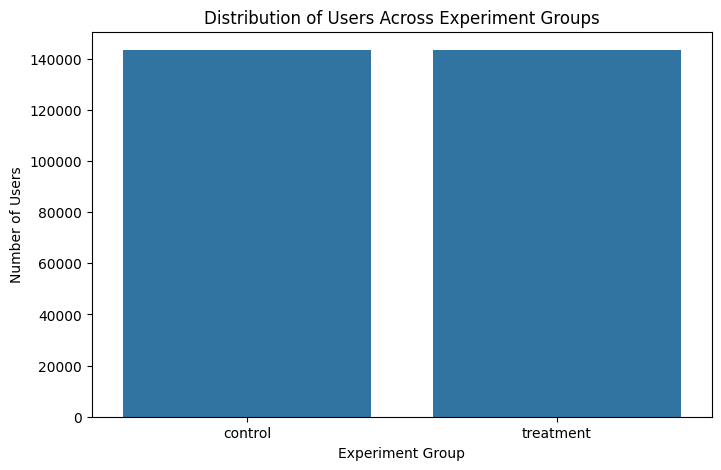

In [40]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='GROUP'
)

plt.title('Distribution of Users Across Experiment Groups')
plt.xlabel('Experiment Group')
plt.ylabel('Number of Users')

plt.show()

#### Findings: Distribution of Users Across Experiment Groups

The cleaned dataset contains 286,690 unique users distributed
almost equally between the two experiment groups.

- Control group: 143,293 users (49.98%).
- Treatment group: 143,397 users (50.02%).

The difference between the groups is only 104 users,
indicating a highly balanced distribution.

This provides a suitable basis for comparing conversion
performance between the existing and redesigned landing pages.
However, similar group sizes alone do not establish that
the experiment was fully randomised.

### Conversion Outcomes by Experiment Group

This section examines the number of successful conversions
and non-conversions recorded in each experiment group.

The comparison provides an initial view of how users
responded to the existing and redesigned landing pages.

In [41]:
conversion_counts = pd.crosstab(
    df_clean['GROUP'],
    df_clean['CONVERTED']
)

conversion_counts

CONVERTED,0,1
GROUP,,
control,126073,17220
treatment,126372,17025


#### Findings: Conversion Outcomes by Experiment Group

The conversion outcome comparison produced the following results:

- Control group: 17,220 successful sign-ups and 126,073
  non-conversions.
- Treatment group: 17,025 successful sign-ups and 126,372
  non-conversions.

The control group recorded 195 more successful sign-ups than
the treatment group, despite having slightly fewer users.

However, conversion counts alone do not establish which landing
page performed better because the experiment groups have
slightly different sample sizes.

Conversion rates will therefore be calculated to enable
a fair comparison of performance between the two groups.

In [42]:
conversion_rates = (
    df_clean.groupby('GROUP')['CONVERTED']
    .mean()
    .mul(100)
)

conversion_rates

,CONVERTED
GROUP,
control,12.017335
treatment,11.872633


#### Findings: Conversion Rate Comparison

The conversion rates were calculated by dividing the number of
successful conversions by the total number of users in each
experiment group.

The results were:

- Control group: 12.0173%.
- Treatment group: 11.8726%.

The treatment group recorded a conversion rate approximately
0.1447 percentage points lower than the control group.

This indicates that the redesigned landing page did not
demonstrate an initial improvement in the observed conversion
rate.

However, the difference is relatively small, and its statistical
significance has not yet been established.

Hypothesis testing will be conducted to determine whether
the observed difference represents a statistically significant
change in conversion performance.

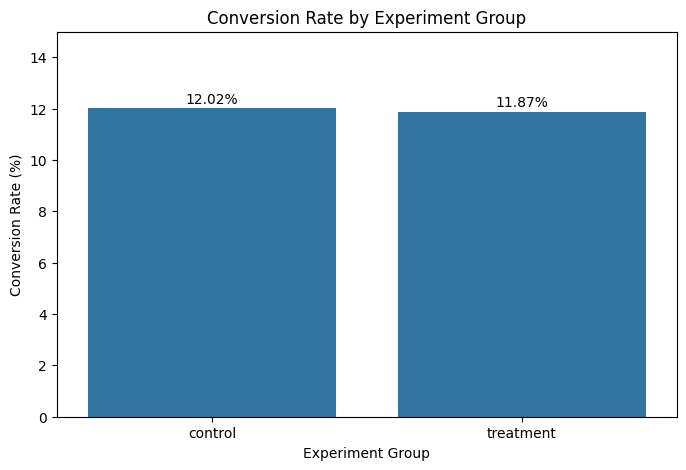

In [43]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=conversion_rates.index,
    y=conversion_rates.values
)

plt.title('Conversion Rate by Experiment Group')
plt.xlabel('Experiment Group')
plt.ylabel('Conversion Rate (%)')

plt.ylim(0, 15)

for i, value in enumerate(conversion_rates.values):
    plt.text(
        i,
        value + 0.2,
        f'{value:.2f}%',
        ha='center'
    )

plt.show()

# **A/B Testing and Statistical Analysis**

## A/B Testing and Statistical Analysis

The statistical analysis evaluates whether the observed difference
in conversion rates between the control and treatment groups
is statistically significant.

The analysis uses a two-tailed hypothesis test.

### Hypothesis Formulation

**Null Hypothesis (H₀):**

There is no difference in conversion rates between the existing
and redesigned landing pages.

**Alternative Hypothesis (H₁):**

There is a difference in conversion rates between the existing
and redesigned landing pages.

The significance level is set at 0.05 (5%).

The test will determine whether sufficient statistical evidence
exists to reject the null hypothesis.

In [44]:
from statsmodels.stats.proportion import proportions_ztest
# Successful conversions in each group
successes = [
    conversion_counts.loc['treatment', 1],
    conversion_counts.loc['control', 1]
]

# Total users in each group
sample_sizes = [
    df_clean[df_clean['GROUP'] == 'treatment'].shape[0],
    df_clean[df_clean['GROUP'] == 'control'].shape[0]
]

successes, sample_sizes

([np.int64(17025), np.int64(17220)], [143397, 143293])

### Understanding the Interpretation of a Two-Proportion Z-Test

A two-proportion z-test produces two main statistical outputs: the Z-statistic and the p-value. These are interpreted alongside a predetermined significance level (α) to determine whether there is sufficient statistical evidence of a difference between two population proportions.

**1. Z-statistic**

The Z-statistic measures how far the observed difference between two sample proportions is from the difference assumed under the null hypothesis, expressed in standard errors.

- A positive Z-statistic indicates that the first proportion is higher than the second, based on the order in which the groups are supplied to the test.
- A negative Z-statistic indicates that the first proportion is lower than the second.
- A Z-statistic close to zero indicates that the observed difference is small relative to its standard error.
- A larger absolute Z-statistic indicates that the observed difference is further from the null-hypothesised difference in standard-error terms.

**2. P-value**

The p-value represents the probability, assuming the null hypothesis is true, of obtaining a test statistic at least as extreme as the one observed.

For a two-tailed test, this considers extreme results in either direction.

- A small p-value indicates that the observed difference would be relatively unlikely if the null hypothesis were true, providing evidence against it.
- A large p-value indicates that the observed result is reasonably compatible with the null hypothesis and provides insufficient evidence to establish a difference.

The p-value does not represent the probability that the null hypothesis is true or false.

**3. Significance Level (α)**

The significance level is the threshold selected before conducting the hypothesis test. It determines how much evidence is required to reject the null hypothesis.

A significance level of 0.05 is commonly used, representing a 5% probability of rejecting a true null hypothesis under the test's assumptions.

**4. Statistical Decision**

The p-value is compared with the selected significance level:

- If the p-value is less than or equal to α, reject the null hypothesis. There is sufficient statistical evidence of a difference between the population proportions.
- If the p-value is greater than α, fail to reject the null hypothesis. There is insufficient statistical evidence to establish a difference between the population proportions.

Failing to reject the null hypothesis does not prove that the population proportions are equal. Similarly, rejecting the null hypothesis does not automatically mean that the observed difference is large or practically important.

**5. Practical Interpretation**

Statistical significance should be distinguished from practical or business significance. A statistically significant difference may be too small to justify a business change, while a potentially meaningful difference may not be statistically significant.

The statistical decision should therefore be considered alongside the size and direction of the observed difference, its confidence interval, and the practical implications for the business.

In [45]:
# Performing the test

z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=sample_sizes,
    alternative='two-sided'
)

print("Z-statistic:", z_stat)
print("P-value:", p_value)

Z-statistic: -1.1944850812796501
P-value: 0.23228827305833621


### Hypothesis Test Results and Interpretation

A two-proportion z-test was conducted to determine whether
the difference in conversion rates between the control and
treatment groups was statistically significant.

The test produced the following results:

- Z-statistic: -1.1945
- P-value: 0.2323
- Significance level: 0.05

Since the p-value (0.2323) is greater than the significance
level (0.05), the null hypothesis is not rejected.

Although the treatment group recorded a slightly lower
conversion rate than the control group, the difference is
not statistically significant.

There is therefore insufficient statistical evidence to
conclude that the redesigned landing page changed the
conversion rate.

Failing to reject the null hypothesis does not establish
that the two landing pages perform identically. It indicates
that the observed experiment results do not provide sufficient
evidence of a difference.

In [46]:
# Confidence Interval for the Difference in Conversion Rates

from statsmodels.stats.proportion import confint_proportions_2indep

ci_lower, ci_upper = confint_proportions_2indep(
    count1=successes[0],
    nobs1=sample_sizes[0],
    count2=successes[1],
    nobs2=sample_sizes[1],
    method='newcomb',
    compare='diff',
    alpha=0.05
)

print("95% Confidence Interval:")
print(f"Lower bound: {ci_lower:.6f}")
print(f"Upper bound: {ci_upper:.6f}")

print("\n95% Confidence Interval (percentage points):")
print(f"Lower bound: {ci_lower * 100:.4f}")
print(f"Upper bound: {ci_upper * 100:.4f}")

95% Confidence Interval:
Lower bound: -0.003821
Upper bound: 0.000927

95% Confidence Interval (percentage points):
Lower bound: -0.3821
Upper bound: 0.0927


### Confidence Interval Results and Interpretation

A 95% confidence interval was calculated to estimate the plausible range of the difference in conversion rates between the treatment and control groups.

The results were:

- Lower bound: -0.3821 percentage points
- Upper bound: 0.0927 percentage points

The confidence interval ranges from -0.3821 to 0.0927 percentage points.

Since the interval includes zero, the results are compatible with the possibility that there is no difference in the population conversion rates between the two landing pages.

The interval also indicates that the true difference could favour either page: the redesigned page could perform slightly worse or slightly better than the existing page.

This finding is consistent with the two-proportion z-test, which did not identify a statistically significant difference between the groups.

Overall, the confidence interval does not provide sufficient evidence to conclude that the redesigned landing page improves conversion performance.

In [47]:
control_rate = conversion_rates.loc['control'] / 100
treatment_rate = conversion_rates.loc['treatment'] / 100

control_conversions_per_1000 = control_rate * 1000
treatment_conversions_per_1000 = treatment_rate * 1000

conversion_difference_per_1000 = (
    treatment_conversions_per_1000 - control_conversions_per_1000
)

print("Expected conversions per 1,000 visitors:")
print(f"Control: {control_conversions_per_1000:.2f}")
print(f"Treatment: {treatment_conversions_per_1000:.2f}")

print(
    "Difference (treatment - control): "
    f"{conversion_difference_per_1000:.2f}"
)

Expected conversions per 1,000 visitors:
Control: 120.17
Treatment: 118.73
Difference (treatment - control): -1.45


### Practical Significance of the Results

To assess the practical implications of the observed conversion-rate difference, the conversion rates were translated into expected conversions per 1,000 visitors.

The results were:

- Control: approximately 120.17 conversions per 1,000 visitors.
- Treatment: approximately 118.73 conversions per 1,000 visitors.
- Difference: approximately 1.45 fewer conversions per 1,000 visitors for the treatment group.

The redesigned landing page therefore recorded a slightly lower observed conversion rate than the existing page.

However, the difference is small in practical terms and was not statistically significant. The results do not provide sufficient evidence to justify adopting or rejecting the redesigned page solely on the basis of this experiment.

The business should consider further testing or additional evidence before making a final implementation decision.

In [48]:
# Conversion Performance Over Time

daily_summary = (
    df_clean.assign(DATE=df_clean['TIMESTAMP'].dt.date)
    .groupby(['DATE', 'GROUP'])
    .agg(
        VISITORS=('USER_ID', 'count'),
        CONVERSIONS=('CONVERTED', 'sum')
    )
    .reset_index()
)

daily_summary['CONVERSION_RATE'] = (
    daily_summary['CONVERSIONS'] /
    daily_summary['VISITORS'] * 100
)

daily_summary.head(10)

,DATE,GROUP,VISITORS,CONVERSIONS,CONVERSION_RATE
0,2017-01-02,control,2813,354,12.584429
1,2017-01-02,treatment,2818,336,11.923350
2,2017-01-03,control,6494,738,11.364336
3,2017-01-03,treatment,6531,745,11.407135
4,2017-01-04,control,6481,787,12.143188
5,2017-01-04,treatment,6448,753,11.678040
6,2017-01-05,control,6330,780,12.322275
7,2017-01-05,treatment,6418,734,11.436585
8,2017-01-06,control,6518,750,11.506597
9,2017-01-06,treatment,6650,822,12.360902


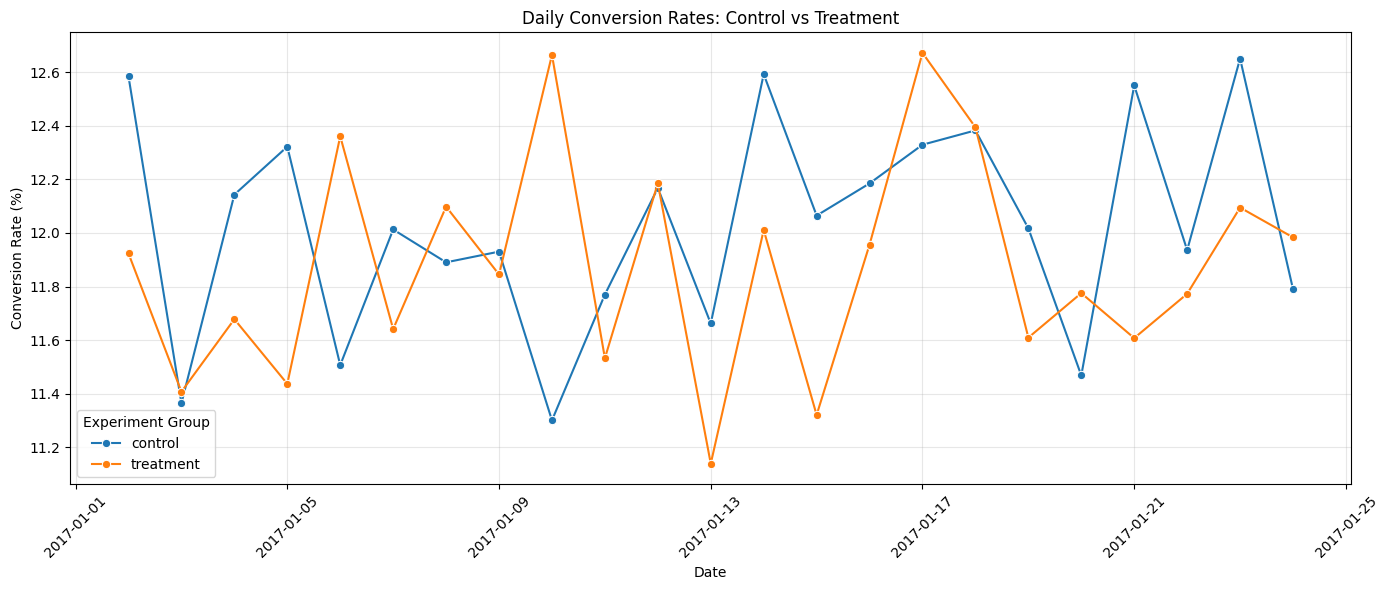

In [49]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_summary,
    x='DATE',
    y='CONVERSION_RATE',
    hue='GROUP',
    marker='o'
)

plt.title('Daily Conversion Rates: Control vs Treatment')
plt.xlabel('Date')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=45)
plt.legend(title='Experiment Group')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Daily Conversion Rate Trends and Interpretation

The daily conversion rate visualisation shows fluctuations in both the control and treatment groups throughout the experiment period.

The two groups frequently alternated in their daily performance. On some days, the control group recorded a higher conversion rate, while on other days, the treatment group performed better.

Neither group demonstrated a consistent advantage across the testing period. Both groups also experienced broadly similar ranges of daily conversion rates.

These fluctuations suggest that daily performance varied throughout the experiment. However, the visual differences between the groups should not be interpreted as evidence of a statistically significant daily advantage.

Overall, the daily trends support the earlier observation that the redesigned landing page did not demonstrate a consistent conversion-rate improvement over the existing page.

In [50]:
#Comparing Daily Conversion Rate Differences

daily_comparison = (
    daily_summary.pivot(
        index='DATE',
        columns='GROUP',
        values='CONVERSION_RATE'
    )
    .reset_index()
)

daily_comparison['TREATMENT_MINUS_CONTROL'] = (
    daily_comparison['treatment'] -
    daily_comparison['control']
)

daily_comparison.head()

GROUP,DATE,control,treatment,TREATMENT_MINUS_CONTROL
0,2017-01-02,12.584429,11.923350,-0.661080
1,2017-01-03,11.364336,11.407135,0.042799
2,2017-01-04,12.143188,11.678040,-0.465148
3,2017-01-05,12.322275,11.436585,-0.885690
4,2017-01-06,11.506597,12.360902,0.854305


In [51]:
treatment_better_days = (
    daily_comparison['TREATMENT_MINUS_CONTROL'] > 0
).sum()

control_better_days = (
    daily_comparison['TREATMENT_MINUS_CONTROL'] < 0
).sum()

equal_days = (
    daily_comparison['TREATMENT_MINUS_CONTROL'] == 0
).sum()

largest_treatment_advantage = daily_comparison.loc[
    daily_comparison['TREATMENT_MINUS_CONTROL'].idxmax()
]

largest_control_advantage = daily_comparison.loc[
    daily_comparison['TREATMENT_MINUS_CONTROL'].idxmin()
]

print("Daily Performance Summary")
print("-------------------------")
print("Days treatment performed better:", treatment_better_days)
print("Days control performed better:", control_better_days)
print("Days with equal conversion rates:", equal_days)

print("\nLargest treatment advantage:")
print(largest_treatment_advantage)

print("\nLargest control advantage:")
print(largest_control_advantage)

Daily Performance Summary
-------------------------
Days treatment performed better: 9
Days control performed better: 14
Days with equal conversion rates: 0

Largest treatment advantage:
GROUP
DATE                       2017-01-10
control                      11.30038
treatment                   12.664548
TREATMENT_MINUS_CONTROL      1.364168
Name: 8, dtype: object

Largest control advantage:
GROUP
DATE                       2017-01-21
control                     12.550607
treatment                   11.607419
TREATMENT_MINUS_CONTROL     -0.943188
Name: 19, dtype: object


### Daily Performance Comparison and Interpretation

A comparison of daily conversion rates showed that the treatment group recorded a higher conversion rate on 9 of the 23 experiment days, while the control group performed better on the remaining 14 days.

The largest treatment advantage occurred on 10 January 2017, when the redesigned page recorded a conversion rate 1.36 percentage points higher than the existing page.

The largest control advantage occurred on 21 January 2017, when the existing page recorded a conversion rate 0.94 percentage points higher than the redesigned page.

Although the control group performed better on more days, the daily differences varied in both magnitude and direction. The treatment group also recorded some days with higher conversion rates.

These findings indicate that neither page maintained a consistent daily performance advantage. The daily comparison is descriptive and does not replace the overall statistical hypothesis test.

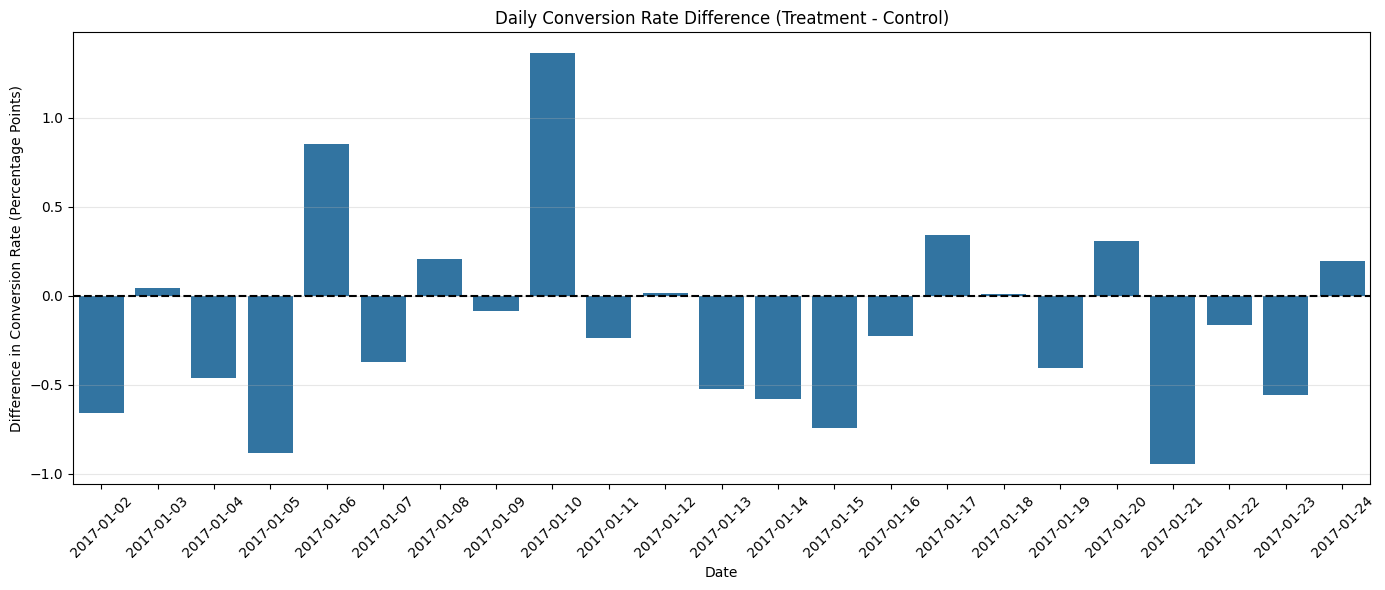

In [52]:
#Visualising Daily Conversion Rate Differences
plt.figure(figsize=(14, 6))

sns.barplot(
    data=daily_comparison,
    x='DATE',
    y='TREATMENT_MINUS_CONTROL'
)

plt.axhline(y=0, color='black', linestyle='--')

plt.title('Daily Conversion Rate Difference (Treatment - Control)')
plt.xlabel('Date')
plt.ylabel('Difference in Conversion Rate (Percentage Points)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Daily Conversion Rate Difference Visualisation

The daily conversion rate difference chart illustrates the variation in performance between the treatment and control groups throughout the experiment.

The horizontal zero line represents equal conversion rates. Positive bars indicate days when the treatment group performed better, while negative bars indicate days when the control group performed better.The chart shows more negative than positive differences, consistent with the control group's higher daily conversion rate on 14 of the 23 experiment days.

The largest positive difference occurred on 10 January 2017, while the largest negative difference occurred on 21 January 2017.Overall, the visualisation reinforces the finding that daily performance fluctuated, with neither landing page maintaining a consistent advantage throughout the experiment.

In [53]:
#Examining Daily Visitor Distribution

daily_visitors = (
    daily_summary.pivot(
        index='DATE',
        columns='GROUP',
        values='VISITORS'
    )
    .reset_index()
)

daily_visitors['VISITOR_DIFFERENCE'] = (
    daily_visitors['treatment'] -
    daily_visitors['control']
)

daily_visitors.head()

GROUP,DATE,control,treatment,VISITOR_DIFFERENCE
0,2017-01-02,2813,2818,5
1,2017-01-03,6494,6531,37
2,2017-01-04,6481,6448,-33
3,2017-01-05,6330,6418,88
4,2017-01-06,6518,6650,132


In [54]:
print("Daily Visitor Distribution")
print("--------------------------")

print("\nAverage daily visitors:")
print(daily_visitors[['control', 'treatment']].mean())

print("\nTotal visitors across the experiment:")
print(daily_visitors[['control', 'treatment']].sum())

print("\nDaily visitor difference:")
print(daily_visitors['VISITOR_DIFFERENCE'].describe())

print(
    "\nLargest absolute daily visitor difference:",
    daily_visitors['VISITOR_DIFFERENCE'].abs().max()
)

Daily Visitor Distribution
--------------------------

Average daily visitors:
GROUP
control      6230.130435
treatment    6234.652174
dtype: float64

Total visitors across the experiment:
GROUP
control      143293
treatment    143397
dtype: int64

Daily visitor difference:
count     23.000000
mean       4.521739
std       89.226917
min     -199.000000
25%      -60.500000
50%        5.000000
75%       64.000000
max      163.000000
Name: VISITOR_DIFFERENCE, dtype: float64

Largest absolute daily visitor difference: 199


### Daily Visitor Distribution and Interpretation

An examination of daily visitor counts showed that the control and treatment groups received broadly comparable numbers of visitors throughout the experiment.The average daily visitor counts were approximately 6,230 for the control group and 6,235 for the treatment group.

Across the entire experiment, the control group recorded 143,293 visitors, while the treatment group recorded 143,397 visitors, representing a difference of only 104 visitors.Daily visitor differences ranged from 199 fewer treatment visitors to 163 more treatment visitors, with an average difference of approximately 5 visitors.

These findings indicate that the two groups had reasonably balanced visitor distributions. Consequently, the overall conversion-rate comparison is based on similarly sized experimental groups.This supports the comparability of the group sample sizes, although it does not independently establish that the experiment was perfectly randomised or free from other sources of bias.

# **Overall Findings from the Time-Based Analysis**

The time-based analysis revealed fluctuations in daily conversion rates for both experimental groups. Although the control group recorded higher conversion rates on more days, the treatment group also outperformed the control group on several occasions.

Neither landing page demonstrated a consistent daily conversion advantage throughout the experiment.The daily visitor distribution was reasonably balanced, with only a small difference in total visitor numbers between the groups.

Overall, the time-based findings reinforce the earlier statistical results: the redesigned landing page did not demonstrate a consistent or statistically significant improvement in conversion performance over the existing page.

# **## Business Recommendations**

### a.Recommended Business Action

Based on the experimental findings, the company should retain its existing landing page rather than immediately implement the redesigned version.The existing landing page recorded a conversion rate of 12.02%, compared with 11.87% for the redesigned page. Although the difference was relatively small, the treatment group did not demonstrate a statistically significant improvement in conversion performance.

The hypothesis test produced a p-value of 0.2323, while the 95% confidence interval ranged from -0.3821 to 0.0927 percentage points. These results do not provide sufficient evidence that the redesigned page improves sign-up conversion.

### b. Recommendations for Future Action

1. **Retain the existing landing page:** Continue using the existing version until further evidence supports adopting the redesign.

2. **Review the redesigned page:** Examine its design, content, navigation and sign-up process to identify potential areas for improvement.

3. **Conduct further experimentation:** If the redesigned page is improved, conduct another controlled A/B test with clearly defined experimental assignments and sufficient sample size.

4. **Strengthen experiment monitoring:** Monitor conversion performance, visitor allocation and data quality throughout future experiments to identify inconsistencies early.

5. **Use statistical and business evidence together:** Future implementation decisions should consider conversion-rate differences, statistical significance and the practical value of any improvement.

### c. Final Business Conclusion

The experiment did not establish that the redesigned landing page improves sign-up conversion compared with the existing page. The existing page recorded a marginally higher observed conversion rate, while the statistical analysis found insufficient evidence of a meaningful difference.The recommended decision is therefore to retain the existing landing page for now and consider further testing before implementing the redesign.